In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, UnidentifiedImageError
from io import BytesIO
from collections import Counter
from datasets import Image as HFImage

import warnings
warnings.filterwarnings("ignore")

In [3]:
from datasets import load_dataset

dataset = load_dataset("hassanjbara/AI4MARS")

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['image', 'label_mask', 'rover_mask', 'range_mask', 'has_masks', 'has_labels'],
        num_rows: 18130
    })
    test_min1: Dataset({
        features: ['image', 'label_mask', 'rover_mask', 'range_mask', 'has_masks', 'has_labels'],
        num_rows: 322
    })
    test_min2: Dataset({
        features: ['image', 'label_mask', 'rover_mask', 'range_mask', 'has_masks', 'has_labels'],
        num_rows: 322
    })
    test_min3: Dataset({
        features: ['image', 'label_mask', 'rover_mask', 'range_mask', 'has_masks', 'has_labels'],
        num_rows: 322
    })
})


### Dataset Integrity Audit

In [ ]:
# Disable auto Image Decoding
image_columns = [
    "image",
    "label_mask",
    "rover_mask",
    "range_mask"
]

raw_datasets = {}

for split, data in dataset.items():
    raw_data = data
    for column in image_columns:
        raw_data = raw_data.cast_column(
            column,
            HFImage(decode=False)
        )

    raw_datasets[split] = raw_data

In [ ]:
# Image Validation Function
def validate_image(image_data):
    if image_data is None:
        return False

    try:
        image_bytes = image_data.get("bytes")

        if image_bytes is not None:
            img = Image.open(BytesIO(image_bytes))
        else:
            img = Image.open(image_data["path"])
        img.verify()
        return True

    except Exception:
        return False

In [6]:
# Detect corrupted images and masks
integrity_results = []

for split, data in raw_datasets.items():
    print(f"\nChecking {split}...")
    invalid_counts = Counter()
    missing_counts = Counter()

    for i in range(len(data)):
        sample = data[i]
        for column in image_columns:
            image_data = sample[column]
            if image_data is None:
                missing_counts[column] += 1

            elif not validate_image(image_data):
                invalid_counts[column] += 1

    for column in image_columns:
        integrity_results.append({
            "split": split,
            "feature": column,
            "missing": missing_counts[column],
            "corrupted": invalid_counts[column]
        })

    print("Missing:", dict(missing_counts))
    print("Corrupted:", dict(invalid_counts))

integrity_df = pd.DataFrame(integrity_results)
display(integrity_df)


Checking train...
Missing: {'label_mask': 2066, 'range_mask': 34, 'rover_mask': 33}
Corrupted: {'image': 3}

Checking test_min1...
Missing: {}
Corrupted: {}

Checking test_min2...
Missing: {}
Corrupted: {}

Checking test_min3...
Missing: {}
Corrupted: {}


,split,feature,missing,corrupted
0,train,image,0,3
1,train,label_mask,2066,0
2,train,rover_mask,33,0
3,train,range_mask,34,0
4,test_min1,image,0,0
5,test_min1,label_mask,0,0
6,test_min1,rover_mask,0,0
7,test_min1,range_mask,0,0
8,test_min2,image,0,0
9,test_min2,label_mask,0,0


In [7]:
# Image Dimension and Modes
dimension_stats = []

for split, data in raw_datasets.items():
    sizes = Counter()
    modes = Counter()

    checked = 0

    for i in range(min(200, len(data))):

        sample = data[i]
        image_data = sample["image"]

        if not validate_image(image_data):
            continue

        try:
            if image_data.get("bytes") is not None:
                img = Image.open(
                    BytesIO(image_data["bytes"])
                )
            else:
                img = Image.open(image_data["path"])

            sizes[img.size] += 1
            modes[img.mode] += 1
            checked += 1

        except Exception:
            continue

    dimension_stats.append({
        "split": split,
        "checked": checked,
        "sizes": dict(sizes),
        "modes": dict(modes)
    })

display(pd.DataFrame(dimension_stats))

,split,checked,sizes,modes
0,train,200,"{(1024, 1024): 200}",{'L': 200}
1,test_min1,200,"{(1024, 1024): 200}",{'L': 200}
2,test_min2,200,"{(1024, 1024): 200}",{'L': 200}
3,test_min3,200,"{(1024, 1024): 200}",{'L': 200}


### Corrupted Images Identification

In [8]:
# Identify corrupted image indices
corrupted_indices = {}

for split, data in raw_datasets.items():
    corrupted = []

    for i in range(len(data)):
        image_data = data[i]["image"]
        if not validate_image(image_data):
            corrupted.append(i)
    corrupted_indices[split] = corrupted

    if corrupted:
        print(f"{split}: {corrupted}")
    else:
        print(f"{split}: No corrupted original images.")

train: [8990, 12577, 17053]
test_min1: No corrupted original images.
test_min2: No corrupted original images.
test_min3: No corrupted original images.


In [9]:
# Verify label-mask dimensions and pixel values
mask_pixel_values = Counter()
mask_dimension_stats = Counter()
checked_masks = 0

train_raw = raw_datasets["train"]

for i in range(len(train_raw)):
    sample = train_raw[i]

    if not sample["has_labels"]:
        continue
    if i in corrupted_indices["train"]:
        continue

    mask_data = sample["label_mask"]
    if not validate_image(mask_data):
        continue

    try:
        if mask_data.get("bytes") is not None:
            mask = Image.open(BytesIO(mask_data["bytes"]))
        else:
            mask = Image.open(mask_data["path"])

        mask_dimension_stats[mask.size] += 1
        mask_pixel_values.update(np.unique(np.array(mask)).tolist())

        checked_masks += 1

        if checked_masks >= 200:
            break

    except Exception:
        continue

print("Masks inspected:", checked_masks)
print("Mask dimensions:", dict(mask_dimension_stats))
print("Unique pixel values:", sorted(mask_pixel_values))

Masks inspected: 200
Mask dimensions: {(1024, 1024): 200}
Unique pixel values: [0, 1, 2, 3, 255]


Sample index: 1
Image size: (1024, 1024)
Mask size: (1024, 1024)


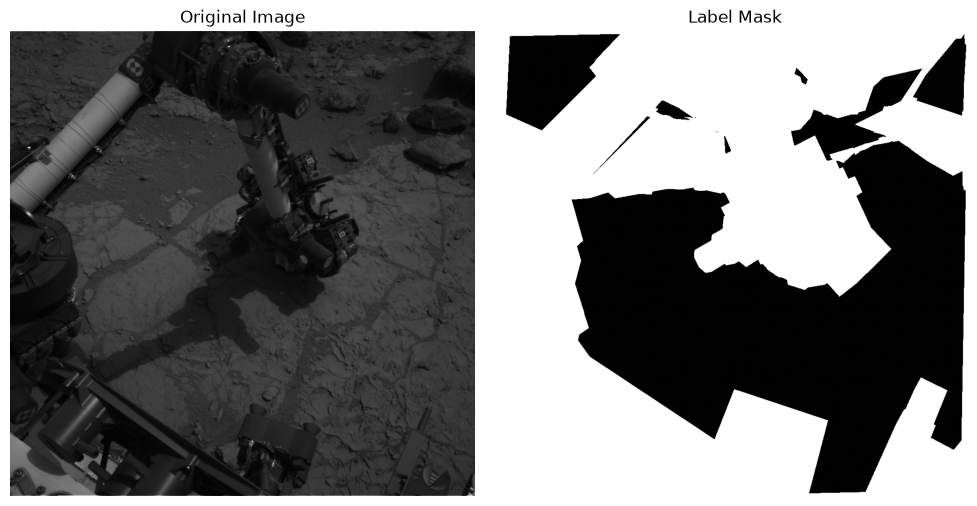

In [10]:
# Image-mask alignment
for i in range(len(train_raw)):
    sample = train_raw[i]

    if not sample["has_labels"]:
        continue

    if i in corrupted_indices["train"]:
        continue

    image_data = sample["image"]
    mask_data = sample["label_mask"]

    if not validate_image(image_data) or not validate_image(mask_data):
        continue

    image = Image.open(
        BytesIO(image_data["bytes"])
        if image_data.get("bytes") is not None
        else image_data["path"]
    )

    mask = Image.open(
        BytesIO(mask_data["bytes"])
        if mask_data.get("bytes") is not None
        else mask_data["path"]
    )

    print("Sample index:", i)
    print("Image size:", image.size)
    print("Mask size:", mask.size)

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    axes[0].imshow(image, cmap="gray")
    axes[0].set_title("Original Image")

    axes[1].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes[1].set_title("Label Mask")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    break

### Mask Preprocessing

In [17]:
# Helper Functions

IGNORE_INDEX = 255
CLASS_NAMES = {0: "Soil", 1: "Bedrock", 2: "Sand", 3: "Big Rock"}
VALID_LABELS = {0, 1, 2, 3, 255}

# Decode a decode=False Hugging Face image dict into a PIL image.
def decode_raw_image(image_data):
    if image_data is None: # Image doesn't exist
        return None
    try:
        if image_data.get("bytes") is not None: # Encoded image data stored directly in memory
            img = Image.open(BytesIO(image_data["bytes"])) 
        else:
            img = Image.open(image_data["path"]) # Path of the image file
        img.load() # Force Image Decoding
        return img
    except Exception:
        return None


# PIL image/mask into a 2D NumPy array.
def to_2d_array(pil_img):
    if pil_img is None:
        return None
    arr = np.array(pil_img)
    return arr[..., 0] if arr.ndim == 3 else arr # Channel Selection from RGB

In [18]:
# Mask preprocessing function

def apply_exclusions(label, rover=None, range_=None):
    """
    label  : 2D array with values in {0,1,2,3,255} 
    rover  : 2D binary array or None
    range_ : 2D binary array or None
    Returns (processed_label, info_dict). Inputs are never modified.
    """
    processed = label.astype(np.uint8).copy() # Copy of the original label
    already_ignored = (label == IGNORE_INDEX) 

    info = {
        "rover_applied": rover is not None,
        "range_applied": range_ is not None,
        "rover_new_ignored": 0,
        "range_new_ignored": 0,
        "overlap_new_ignored": 0,
    }

    rover_region = None
    range_region = None

    if rover is not None:
        if rover.shape != label.shape:
            raise ValueError(f"rover shape {rover.shape} != label shape {label.shape}")
        rover_region = rover > 0
        info["rover_new_ignored"] = int((rover_region & ~already_ignored).sum())
        processed[rover_region] = IGNORE_INDEX

    if range_ is not None:
        if range_.shape != label.shape:
            raise ValueError(f"range shape {range_.shape} != label shape {label.shape}")
        range_region = range_ > 0
        info["range_new_ignored"] = int((range_region & ~already_ignored).sum()) 
        processed[range_region] = IGNORE_INDEX

    if rover_region is not None and range_region is not None:
        info["overlap_new_ignored"] = int(
            (rover_region & range_region & ~already_ignored).sum()
        )

    return processed, info

In [23]:
# One sample Validation
train_raw = raw_datasets["train"]
has_labels = np.array(train_raw["has_labels"])
bad_idx = set(corrupted_indices["train"])

def validate_sample(split_data, idx):
    """Run apply_exclusions on one row and assert every requirement holds."""
    row = split_data[idx]
    image  = decode_raw_image(row["image"])
    label  = to_2d_array(decode_raw_image(row["label_mask"]))
    rover  = to_2d_array(decode_raw_image(row["rover_mask"]))
    range_ = to_2d_array(decode_raw_image(row["range_mask"]))

    label_before = label.copy()
    processed, info = apply_exclusions(label, rover, range_)

    assert set(np.unique(processed).tolist()) <= VALID_LABELS, "Unexpected class IDs"
    assert processed.shape == label.shape == (image.size[1], image.size[0]), "Shape mismatch"
    assert np.array_equal(label, label_before), "Source label was modified"
    assert np.all(processed[label == 255] == 255), "Existing 255 changed"
    if rover is not None:
        assert np.all(processed[rover > 0] == 255), "Rover not excluded"
    if range_ is not None:
        assert np.all(processed[range_ > 0] == 255), "Range not excluded"

    return label, processed, info

_, _, info = validate_sample(train_raw, 1)
print("Sample 1 passed:", info)

Sample 1 passed: {'rover_applied': True, 'range_applied': True, 'rover_new_ignored': 0, 'range_new_ignored': 0, 'overlap_new_ignored': 0}


In [24]:
# Synthetic Data Validation

label_syn = np.zeros((10, 10), dtype=np.uint8)
label_syn[0, :] = 255
rover_syn = np.zeros((10, 10), dtype=np.uint8); rover_syn[2:4, 2:4] = 1
range_syn = np.zeros((10, 10), dtype=np.uint8); range_syn[3:5, 3:5] = 1; range_syn[0, 0] = 1

processed_syn, info_syn = apply_exclusions(label_syn, rover_syn, range_syn)

assert info_syn["rover_new_ignored"] == 4
assert info_syn["range_new_ignored"] == 4
assert info_syn["overlap_new_ignored"] == 1
assert (processed_syn == 255).sum() == 10 + 4 + 4 - 1
assert np.all(label_syn[2:4, 2:4] == 0)

_, info_none = apply_exclusions(label_syn, None, None)
assert info_none["rover_applied"] is False and info_none["range_applied"] is False
print("Synthetic tests passed.")

Synthetic tests passed.


**Finding (spot check):** On 700 evenly spaced samples (400 train, 300 test), rover/range
exclusions changed 0 pixels, which suggests labels already contain 255 in those regions.
Confirmed or refuted by the full audit in 2.2.5.

In [31]:
# Rows where a mask feature is missing
def find_missing_rows(data, column, batch_size=256):
    """Return indices of rows where `column` has no data (decode=False dataset)."""
    missing, start = [], 0
    for batch in data.select_columns([column]).iter(batch_size=batch_size):
        items = batch[column]
        for j, item in enumerate(items):
            if item is None or (item.get("bytes") is None and item.get("path") is None):
                missing.append(start + j)
        start += len(items)
    return missing

missing_rover = set(find_missing_rows(train_raw, "rover_mask"))
missing_range = set(find_missing_rows(train_raw, "range_mask"))
print("Missing rover masks:", len(missing_rover), "| Missing range masks:", len(missing_range))

Missing rover masks: 33 | Missing range masks: 34


In [32]:
# Registry of usable training rows
train_status = pd.DataFrame({
    "index": np.arange(len(train_raw)),
    "has_labels": has_labels,
    "corrupted_image": [i in bad_idx for i in range(len(train_raw))],
    "rover_missing": [i in missing_rover for i in range(len(train_raw))],
    "range_missing": [i in missing_range for i in range(len(train_raw))],
})

usable_train = train_status[train_status.has_labels & ~train_status.corrupted_image].copy()
usable_train["exclusion_incomplete"] = usable_train.rover_missing | usable_train.range_missing
usable_train = usable_train[["index", "rover_missing", "range_missing", "exclusion_incomplete"]].reset_index(drop=True)

print("Usable labeled rows:", len(usable_train))
print("Corrupted AND labeled:", int((train_status.corrupted_image & train_status.has_labels).sum()))
display(usable_train[usable_train.exclusion_incomplete])

Usable labeled rows: 16064
Corrupted AND labeled: 0


,index,rover_missing,range_missing,exclusion_incomplete
6225,7211,False,True,True


In [33]:
# Rows with incomplete exclusions
DROP_INCOMPLETE_ROWS = False   # True drops row 7211 (and any like it)

keep = ~usable_train.exclusion_incomplete if DROP_INCOMPLETE_ROWS else slice(None)
train_ids = usable_train.loc[keep, "index"].tolist()
print("Training rows used:", len(train_ids))

Training rows used: 16064


**Finding (missing auxiliary masks):** All 33 missing rover masks are on unlabeled rows
(30 with no masks, 3 corrupted images). Of 34 missing range masks, 33 are on the same
unlabeled rows. Only row 7211 is labeled with a missing range mask; its label is 34.87%
ignored and contains only Bedrock + 255. Decision: keep it, flagged as `exclusion_incomplete`
(switch: `DROP_INCOMPLETE_ROWS`).

In [ ]:
# Full Dataset Audit
from tqdm.auto import tqdm

COUNT_KEYS = [0, 1, 2, 3, 255]

def audit_split(data, indices, split_name):
    records = []
    for i in tqdm(indices, desc=split_name):
        row = data[int(i)]
        label  = to_2d_array(decode_raw_image(row["label_mask"]))
        rover  = to_2d_array(decode_raw_image(row["rover_mask"]))
        range_ = to_2d_array(decode_raw_image(row["range_mask"]))

        processed, info = apply_exclusions(label, rover, range_)

        # Per-row validation
        assert set(np.unique(processed).tolist()) <= VALID_LABELS
        assert processed.shape == label.shape
        assert np.all(processed[label == 255] == 255)
        if rover is not None:
            assert np.all(processed[rover > 0] == 255)
        if range_ is not None:
            assert np.all(processed[range_ > 0] == 255)

        before = np.bincount(label.ravel(), minlength=256)
        after  = np.bincount(processed.ravel(), minlength=256)

        rec = {"split": split_name, "index": int(i), **info}
        for k in COUNT_KEYS:
            rec[f"before_{k}"] = int(before[k])
            rec[f"after_{k}"] = int(after[k])
        records.append(rec)
    return pd.DataFrame(records)

In [35]:
audit_parts = [audit_split(train_raw, train_ids, "train")]

for split in ["test_min1", "test_min2", "test_min3"]:
    data = raw_datasets[split]
    audit_parts.append(audit_split(data, range(len(data)), split))

audit_df = pd.concat(audit_parts, ignore_index=True)
print("Audited rows:", len(audit_df))
print("All per-row assertions passed.")

train:   0%|          | 0/16064 [00:00<?, ?it/s]

test_min1:   0%|          | 0/322 [00:00<?, ?it/s]

test_min2:   0%|          | 0/322 [00:00<?, ?it/s]

test_min3:   0%|          | 0/322 [00:00<?, ?it/s]

Audited rows: 17030
All per-row assertions passed.


In [ ]:
summary = audit_df.groupby("split").agg(
    rows=("index", "count"),
    rows_changed=("rover_new_ignored", lambda s: int(((s > 0) | (audit_df.loc[s.index, "range_new_ignored"] > 0)).sum())),
    rover_new_px=("rover_new_ignored", "sum"),
    range_new_px=("range_new_ignored", "sum"),
    overlap_px=("overlap_new_ignored", "sum"),
    rover_not_applied=("rover_applied", lambda s: int((~s).sum())),
    range_not_applied=("range_applied", lambda s: int((~s).sum())),
)
display(summary)

,rows,rows_changed,rover_new_px,range_new_px,overlap_px,rover_not_applied,range_not_applied
split,,,,,,,
test_min1,322,0,0,0,0,0,0
test_min2,322,0,0,0,0,0,0
test_min3,322,0,0,0,0,0,0
train,16064,0,0,0,0,0,1


In [ ]:
rows = []
for split, df in audit_df.groupby("split"):
    total_px = sum(df[f"before_{k}"].sum() for k in COUNT_KEYS)
    for k in COUNT_KEYS:
        b, a = int(df[f"before_{k}"].sum()), int(df[f"after_{k}"].sum())
        rows.append({
            "split": split,
            "value": k,
            "class": CLASS_NAMES.get(k, "IGNORE"),
            "before_px": b,
            "after_px": a,
            "before_%": round(b / total_px * 100, 3),
            "after_%": round(a / total_px * 100, 3),
        })

dist_df = pd.DataFrame(rows)
display(dist_df[dist_df.split == "train"])

,split,value,class,before_px,after_px,before_%,after_%
15,train,0,Soil,3485135841,3485135841,20.690,20.690
16,train,1,Bedrock,4660855168,4660855168,27.670,27.670
17,train,2,Sand,1126246813,1126246813,6.686,6.686
18,train,3,Big Rock,86225600,86225600,0.512,0.512
19,train,255,IGNORE,7485861442,7485861442,44.441,44.441


**Finding (full audit):** On all 16,064 usable train rows and 966 test rows, rover and range
exclusions changed 0 pixels, so the source labels already contain 255 in those regions.
Exclusions are still applied as a guarantee (per the project guide). Only row 7211 lacked a
range mask. Train ignored pixels: 44.44%. Class shares among labeled pixels:
Soil 37.2%, Bedrock 49.8%, Sand 12.0%, Big Rock 0.9%.

In [38]:
# Visualization helper
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

CLASS_COLORS = ["#c2a15f", "#6b6b6b", "#f2e394", "#d1495b", "#1b1b1b"]  # soil, bedrock, sand, big rock, ignore
label_cmap = ListedColormap(CLASS_COLORS)

def to_display(label):
    """Map 255 -> 4 so a discrete colormap works. Display only, never used for training."""
    vis = label.astype(np.uint8).copy()
    vis[vis == IGNORE_INDEX] = 4
    return vis

def show_five_panel(split_data, idx):
    row = split_data[idx]
    image  = decode_raw_image(row["image"])
    label  = to_2d_array(decode_raw_image(row["label_mask"]))
    rover  = to_2d_array(decode_raw_image(row["rover_mask"]))
    range_ = to_2d_array(decode_raw_image(row["range_mask"]))
    processed, info = apply_exclusions(label, rover, range_)

    fig, axes = plt.subplots(1, 5, figsize=(22, 5))
    axes[0].imshow(image, cmap="gray");                         axes[0].set_title("Image")
    axes[1].imshow(to_display(label), cmap=label_cmap, vmin=0, vmax=4, interpolation="nearest")
    axes[1].set_title("Original label")
    axes[2].imshow(rover, cmap="gray", vmin=0, vmax=1);         axes[2].set_title("Rover mask")
    axes[3].imshow(range_, cmap="gray", vmin=0, vmax=1);        axes[3].set_title("Range mask (>30 m)")
    axes[4].imshow(to_display(processed), cmap=label_cmap, vmin=0, vmax=4, interpolation="nearest")
    axes[4].set_title("Processed label")
    for ax in axes:
        ax.axis("off")

    handles = [Patch(color=c, label=n) for c, n in zip(CLASS_COLORS, ["Soil", "Bedrock", "Sand", "Big Rock", "Ignore (255)"])]
    fig.legend(handles=handles, loc="lower center", ncol=5)
    plt.tight_layout(rect=[0, 0.06, 1, 1])
    plt.show()
    print(f"Sample {idx} | new ignored px: {info['rover_new_ignored'] + info['range_new_ignored']}")

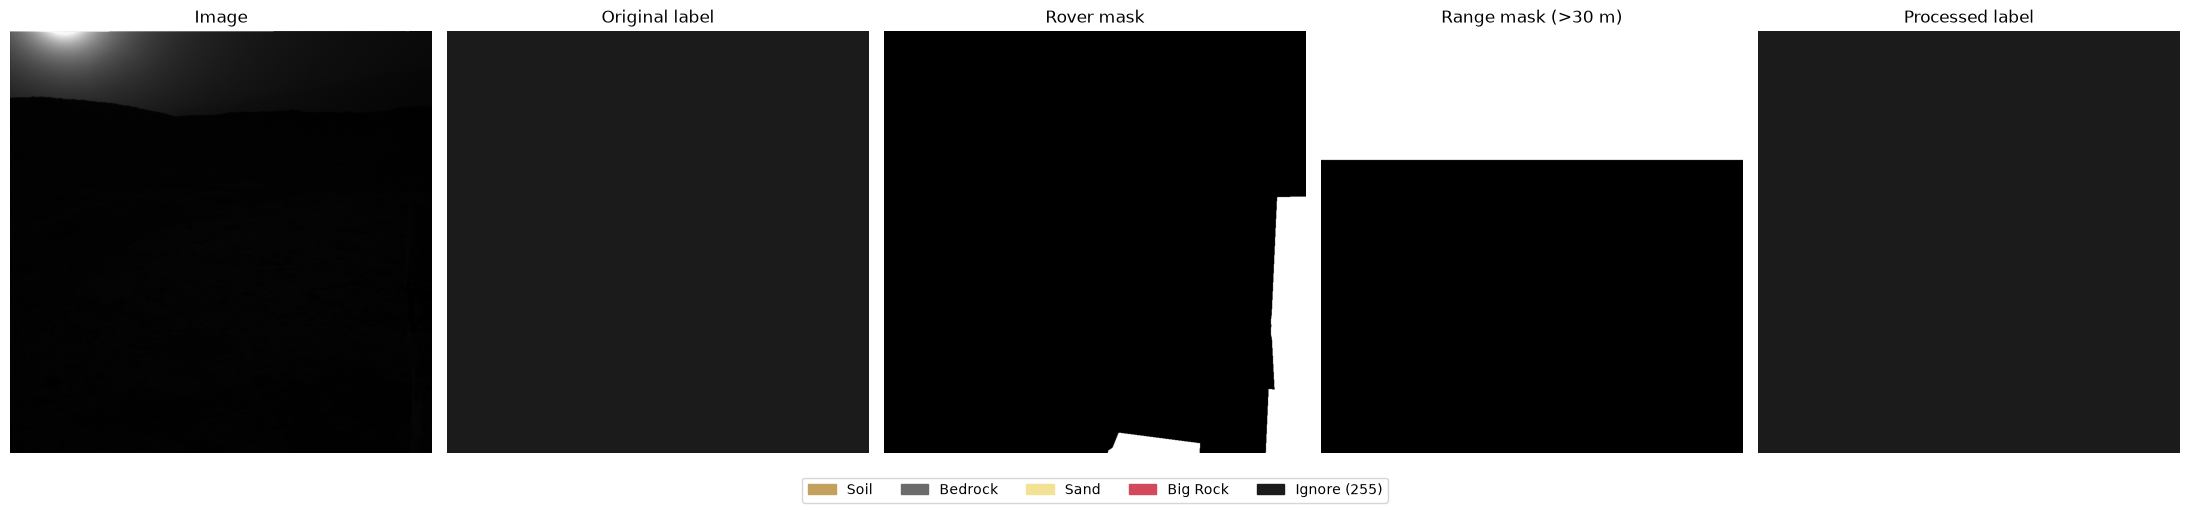

Sample 2 | new ignored px: 0


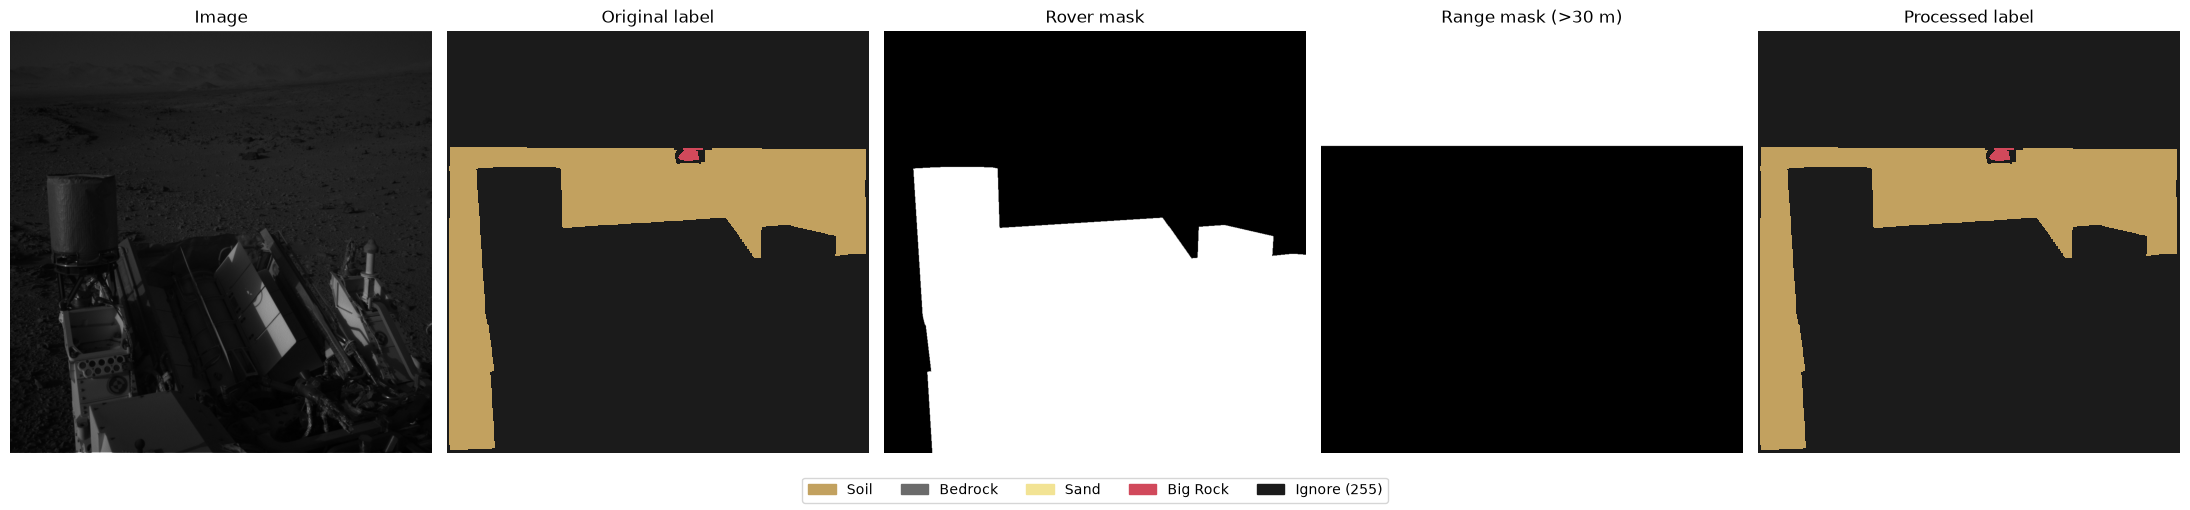

Sample 3 | new ignored px: 0


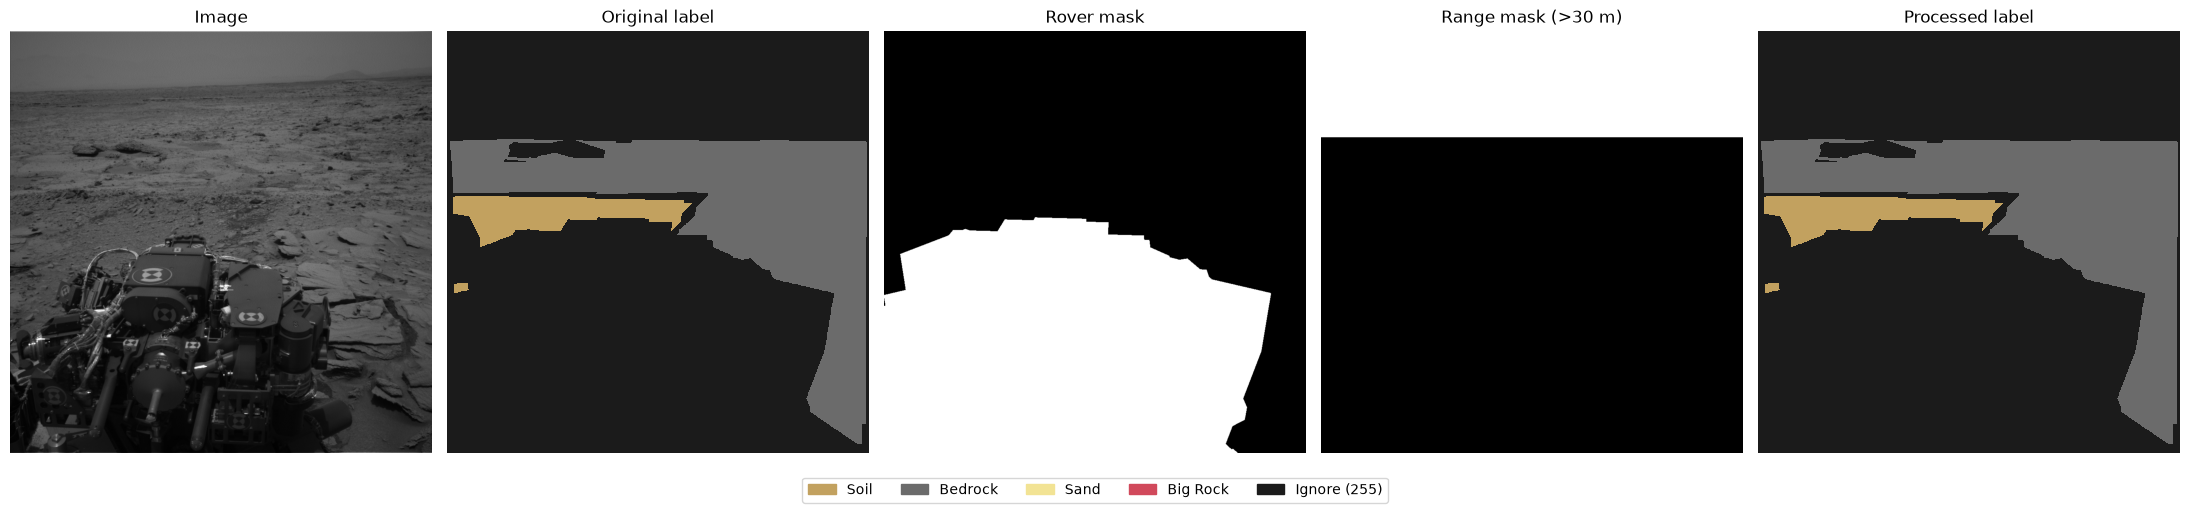

Sample 32 | new ignored px: 0


In [39]:
# Samples that have both a rover region and a far region
shown = 0
for i in train_ids[:300]:
    row = train_raw[i]
    rover  = to_2d_array(decode_raw_image(row["rover_mask"]))
    range_ = to_2d_array(decode_raw_image(row["range_mask"]))
    if rover is not None and range_ is not None and (rover > 0).sum() > 50_000 and (range_ > 0).sum() > 50_000:
        show_five_panel(train_raw, i)
        shown += 1
    if shown == 3:
        break

### Train-Test Split

In [40]:
# Block-wise train/validation split
SEED = 42
VAL_FRACTION = 0.10
BLOCK_SIZE = 100          # consecutive rows kept together

rng = np.random.default_rng(SEED)

ids = np.array(sorted(train_ids))
blocks = [ids[i:i + BLOCK_SIZE] for i in range(0, len(ids), BLOCK_SIZE)]

n_val_blocks = int(round(len(blocks) * VAL_FRACTION))
val_block_ids = set(rng.choice(len(blocks), size=n_val_blocks, replace=False).tolist())

val_ids   = np.concatenate([b for k, b in enumerate(blocks) if k in val_block_ids])
train_split_ids = np.concatenate([b for k, b in enumerate(blocks) if k not in val_block_ids])

# Checks
assert len(set(val_ids) & set(train_split_ids)) == 0, "Overlap between train and val!"
assert len(val_ids) + len(train_split_ids) == len(ids), "Rows lost in split!"

print(f"Train: {len(train_split_ids)} | Val: {len(val_ids)} ({len(val_ids) / len(ids) * 100:.1f}%)")

Train: 14464 | Val: 1600 (10.0%)


In [41]:
# Data Balance check
def class_share(split_name_ids):
    sub = audit_df[(audit_df.split == "train") & (audit_df["index"].isin(split_name_ids))]
    counts = {k: sub[f"after_{k}"].sum() for k in [0, 1, 2, 3]}
    total = sum(counts.values())
    return {CLASS_NAMES[k]: round(v / total * 100, 2) for k, v in counts.items()}

print("Train:", class_share(train_split_ids))
print("Val:  ", class_share(val_ids))

Train: {'Soil': np.float64(37.02), 'Bedrock': np.float64(50.01), 'Sand': np.float64(12.05), 'Big Rock': np.float64(0.92)}
Val:   {'Soil': np.float64(39.21), 'Bedrock': np.float64(47.94), 'Sand': np.float64(11.87), 'Big Rock': np.float64(0.97)}


In [42]:
# Resize functions
IMG_SIZE = 512

def resize_image(image, size=IMG_SIZE):
    """Resize a PIL image with bilinear interpolation (smooth, for pixel intensities)."""
    return image.resize((size, size), resample=Image.BILINEAR)

def resize_label(label, size=IMG_SIZE):
    """Resize a 2D label array with NEAREST interpolation.
    Nearest-neighbor never invents new values, so classes and 255 stay intact."""
    pil_label = Image.fromarray(label.astype(np.uint8), mode="L")
    resized = pil_label.resize((size, size), resample=Image.NEAREST)
    return np.array(resized, dtype=np.uint8)

In [43]:
# Synthetic test, bilinear corrupts labels, nearest does not
label_syn = np.zeros((8, 8), dtype=np.uint8)
label_syn[:, 4:] = 255                                  # sharp 0 | 255 boundary

bilinear = np.array(Image.fromarray(label_syn).resize((4, 4), Image.BILINEAR))
nearest  = resize_label(label_syn, size=4)

print("Bilinear values:", np.unique(bilinear).tolist(), "(may contain invented classes)")
print("Nearest values: ", np.unique(nearest).tolist())
assert set(np.unique(nearest).tolist()) <= {0, 255}

Bilinear values: [0, 32, 223, 255] (may contain invented classes)
Nearest values:  [0, 255]


In [44]:
# Real-sample test on a handful of rows
for idx in train_split_ids[:5]:
    row = train_raw[int(idx)]
    label  = to_2d_array(decode_raw_image(row["label_mask"]))
    rover  = to_2d_array(decode_raw_image(row["rover_mask"]))
    range_ = to_2d_array(decode_raw_image(row["range_mask"]))

    processed, _ = apply_exclusions(label, rover, range_)   # exclusions BEFORE resizing
    resized = resize_label(processed)

    assert resized.shape == (IMG_SIZE, IMG_SIZE)
    assert set(np.unique(resized).tolist()) <= VALID_LABELS, "Invalid class after resize"

    ignore_before = (processed == 255).mean() * 100
    ignore_after  = (resized == 255).mean() * 100
    print(f"Row {idx}: ignored {ignore_before:.2f}% -> {ignore_after:.2f}% | classes: {np.unique(resized).tolist()}")

Row 1: ignored 58.21% -> 58.18% | classes: [0, 1, 3, 255]
Row 2: ignored 100.00% -> 100.00% | classes: [255]
Row 3: ignored 79.19% -> 79.18% | classes: [0, 3, 255]
Row 4: ignored 36.58% -> 36.59% | classes: [0, 255]
Row 5: ignored 67.15% -> 67.15% | classes: [0, 1, 255]


In [47]:
# Filter rows with no usable labels (train/val only; test splits untouched)
TOTAL_PX = 1024 * 1024
MIN_LABELED_FRACTION = 0.0   # keep rows with labeled fraction > this (0.0 drops only 100%-ignored rows)

train_audit = audit_df[audit_df.split == "train"].copy()
train_audit["ignored_frac"] = train_audit["after_255"] / TOTAL_PX
labeled_frac = dict(zip(train_audit["index"], 1.0 - train_audit["ignored_frac"]))

print("Fully ignored rows (100%):", int((train_audit.ignored_frac == 1.0).sum()))
print("Rows >= 95% ignored:      ", int((train_audit.ignored_frac >= 0.95).sum()))

def keep_rows(ids):
    return [int(i) for i in ids if labeled_frac[int(i)] > MIN_LABELED_FRACTION]

train_split_ids_f = keep_rows(train_split_ids)
val_ids_f         = keep_rows(val_ids)

print(f"Train: {len(train_split_ids)} -> {len(train_split_ids_f)}")
print(f"Val:   {len(val_ids)} -> {len(val_ids_f)}")
print("Train shares:", class_share(train_split_ids_f))
print("Val shares:  ", class_share(val_ids_f))

Fully ignored rows (100%): 163
Rows >= 95% ignored:       463
Train: 14464 -> 14312
Val:   1600 -> 1589
Train shares: {'Soil': np.float64(37.02), 'Bedrock': np.float64(50.01), 'Sand': np.float64(12.05), 'Big Rock': np.float64(0.92)}
Val shares:   {'Soil': np.float64(39.21), 'Bedrock': np.float64(47.94), 'Sand': np.float64(11.87), 'Big Rock': np.float64(0.97)}


### Dataset-Dataloader

In [ ]:
# PyTorch Dataset
import torch
from torch.utils.data import Dataset, DataLoader

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)


class Ai4MarsSegmentation(Dataset):
    """Returns (image, label):
        image: float32 tensor (3, H, W), ImageNet-normalized
        label: int64 tensor (H, W) with values in {0,1,2,3,255}
    """

    def __init__(self, raw_split, indices, img_size=IMG_SIZE, normalize=True):
        self.data = raw_split                           # Original dataset split containing images and masks
        self.indices = [int(i) for i in indices]        # Specific row indices that belong to this dataset
        self.img_size = img_size                        # Target image resolution
        self.normalize = normalize                      # Whether to apply ImageNet normalization

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, k):
        idx = self.indices[k]
        row = self.data[idx]

        image  = decode_raw_image(row["image"])
        label  = to_2d_array(decode_raw_image(row["label_mask"]))
        rover  = to_2d_array(decode_raw_image(row["rover_mask"]))
        range_ = to_2d_array(decode_raw_image(row["range_mask"]))

        if image is None:
            raise ValueError(f"Row {idx}: image missing or corrupted")
        if label is None:
            raise ValueError(f"Row {idx}: label mask missing")

        # exclusions at full resolution first, then resize
        label, _ = apply_exclusions(label, rover, range_)
        label = resize_label(label, self.img_size)

        image = resize_image(image.convert("RGB"), self.img_size)
        image = np.asarray(image, dtype=np.float32) / 255.0
        if self.normalize:
            image = (image - IMAGENET_MEAN) / IMAGENET_STD

        image_t = torch.from_numpy(image).permute(2, 0, 1).contiguous()
        label_t = torch.from_numpy(label.astype(np.int64))
        return image_t, label_t

In [49]:
# Build train/val datasets from the filtered ids
train_ds = Ai4MarsSegmentation(raw_datasets["train"], train_split_ids_f)
val_ds   = Ai4MarsSegmentation(raw_datasets["train"], val_ids_f)

print("Train samples:", len(train_ds), "| Val samples:", len(val_ds))

Train samples: 14312 | Val samples: 1589


In [50]:
# Section 2.3.7: Inspect one batch
loader = DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=0)
images, labels = next(iter(loader))

print("Images:", images.shape, images.dtype)
print("Labels:", labels.shape, labels.dtype)
print("Label values in batch:", torch.unique(labels).tolist())
print(f"Image range: [{images.min():.2f}, {images.max():.2f}]")

assert images.shape == (4, 3, IMG_SIZE, IMG_SIZE)
assert labels.shape == (4, IMG_SIZE, IMG_SIZE)
assert images.dtype == torch.float32 and labels.dtype == torch.int64
assert set(torch.unique(labels).tolist()) <= VALID_LABELS
print("Batch checks passed.")

Images: torch.Size([4, 3, 512, 512]) torch.float32
Labels: torch.Size([4, 512, 512]) torch.int64
Label values in batch: [0, 1, 2, 3, 255]
Image range: [-2.05, 2.57]
Batch checks passed.


In [51]:
# Test datasets (official splits, no filtering)
test_datasets = {
    split: Ai4MarsSegmentation(raw_datasets[split], range(len(raw_datasets[split])))
    for split in ["test_min1", "test_min2", "test_min3"]
}

for split, ds in test_datasets.items():
    img, lbl = ds[0]
    assert img.shape == (3, IMG_SIZE, IMG_SIZE) and lbl.shape == (IMG_SIZE, IMG_SIZE)
    assert set(torch.unique(lbl).tolist()) <= VALID_LABELS
    print(f"{split}: {len(ds)} samples | sample 0 OK")

test_min1: 322 samples | sample 0 OK
test_min2: 322 samples | sample 0 OK
test_min3: 322 samples | sample 0 OK


In [52]:
# Save splits for reproducibility
import json
from pathlib import Path

splits_path = Path("../data/splits.json")
splits_path.parent.mkdir(exist_ok=True)

splits = {
    "config": {
        "seed": SEED,
        "val_fraction": VAL_FRACTION,
        "block_size": BLOCK_SIZE,
        "img_size": IMG_SIZE,
        "min_labeled_fraction": MIN_LABELED_FRACTION,
        "drop_incomplete_rows": DROP_INCOMPLETE_ROWS,
    },
    "train": [int(i) for i in train_split_ids_f],
    "val": [int(i) for i in val_ids_f],
}

with open(splits_path, "w") as f:
    json.dump(splits, f)

print("Saved:", splits_path, "|", len(splits["train"]), "train,", len(splits["val"]), "val")

Saved: ../data/splits.json | 14312 train, 1589 val


In [53]:
# Compare with the notebook version
import sys
sys.path.append("..")
from src.data.preprocessing import Ai4MarsSegmentation as SrcDataset

with open("../data/splits.json") as f:
    saved = json.load(f)
assert saved["train"] == [int(i) for i in train_split_ids_f]
assert saved["val"] == [int(i) for i in val_ids_f]

src_ds = SrcDataset(raw_datasets["train"], saved["val"][:5])
nb_ds  = Ai4MarsSegmentation(raw_datasets["train"], saved["val"][:5])

for k in range(5):
    a_img, a_lbl = src_ds[k]
    b_img, b_lbl = nb_ds[k]
    assert torch.equal(a_img, b_img) and torch.equal(a_lbl, b_lbl)

print("src module matches the notebook implementation. Splits reload correctly.")

src module matches the notebook implementation. Splits reload correctly.
